# Uber pickup clustering and forecasting

Revised report. Spatial zones are learned on September 1–23 only, then held fixed for the September 24–30 forecast evaluation. Place the course CSV beside this notebook and run all cells. The code below is the full analysis, with captured outputs from execution.

## 1. Data and study design

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from threadpoolctl import threadpool_limits
threadpool_limits(limits=2)
ROOT = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
FIG = ROOT / 'figures'
FIG.mkdir(exist_ok=True)
DATA = ROOT / 'uber-data.csv'
if not DATA.exists():
    raise FileNotFoundError('Place the instructor-provided uber-data.csv beside this script/notebook.')
df = pd.read_csv(DATA)
duplicates = int(df.duplicated().sum())
missing = df.isna().sum().to_dict()
df['time'] = pd.to_datetime(df['Date/Time'], format='%m/%d/%Y %H:%M:%S', errors='raise')
valid = df.Lat.between(-90,90) & df.Lon.between(-180,180)
if not valid.all() or df[['Lat','Lon']].isna().any().any():
    raise ValueError('Invalid or missing coordinates require review.')
cutoff = pd.Timestamp('2014-09-24')
training = df.time < cutoff
sx = 111.32 * np.cos(np.deg2rad(40.74))
X = np.c_[(df.Lon.to_numpy()+74)*sx, (df.Lat.to_numpy()-40.74)*111.32]
rng = np.random.default_rng(42)
print(f'{len(df):,} records; {df.time.min()} to {df.time.max()}.')
print(f'Missing values: {missing}; exact repeated rows retained: {duplicates:,}.')
print('Spatial model and demand profile trained on Sep 1–23; test period Sep 24–30 22:00.')



1,028,136 records; 2014-09-01 00:00:00 to 2014-09-30 22:59:00.
Missing values: {'Date/Time': 0, 'Lat': 0, 'Lon': 0, 'Base': 0}; exact repeated rows retained: 24,037.
Spatial model and demand profile trained on Sep 1–23; test period Sep 24–30 22:00.


## 2. Choosing a spatial partition using training data only

 k  silhouette  calinski_harabasz  davies_bouldin     inertia  rank_sum
 2      0.6527         11247.0736          0.8703 770411.4112      19.0
 3      0.3907         12745.3900          0.8029 553055.6869      23.0
 4      0.4032         12504.7090          0.8435 446671.6447      23.0
 5      0.4261         13057.6433          0.7539 361541.9273      17.0
 6      0.4410         13979.4596          0.7475 294222.8307      14.0
 7      0.4581         15049.6256          0.6792 242156.9202       9.0
 8      0.4577         15264.3563          0.6438 211746.3008       7.0
 9      0.4087         15460.0494          0.6911 187770.2288      12.0
10      0.4029         15811.5039          0.6721 166864.1079      11.0
Selected k: 8 ; final MiniBatch model quality on training sample: {'silhouette': 0.4673090758085741, 'calinski_harabasz': 14346.48874085466, 'davies_bouldin': 0.7052109850729419}


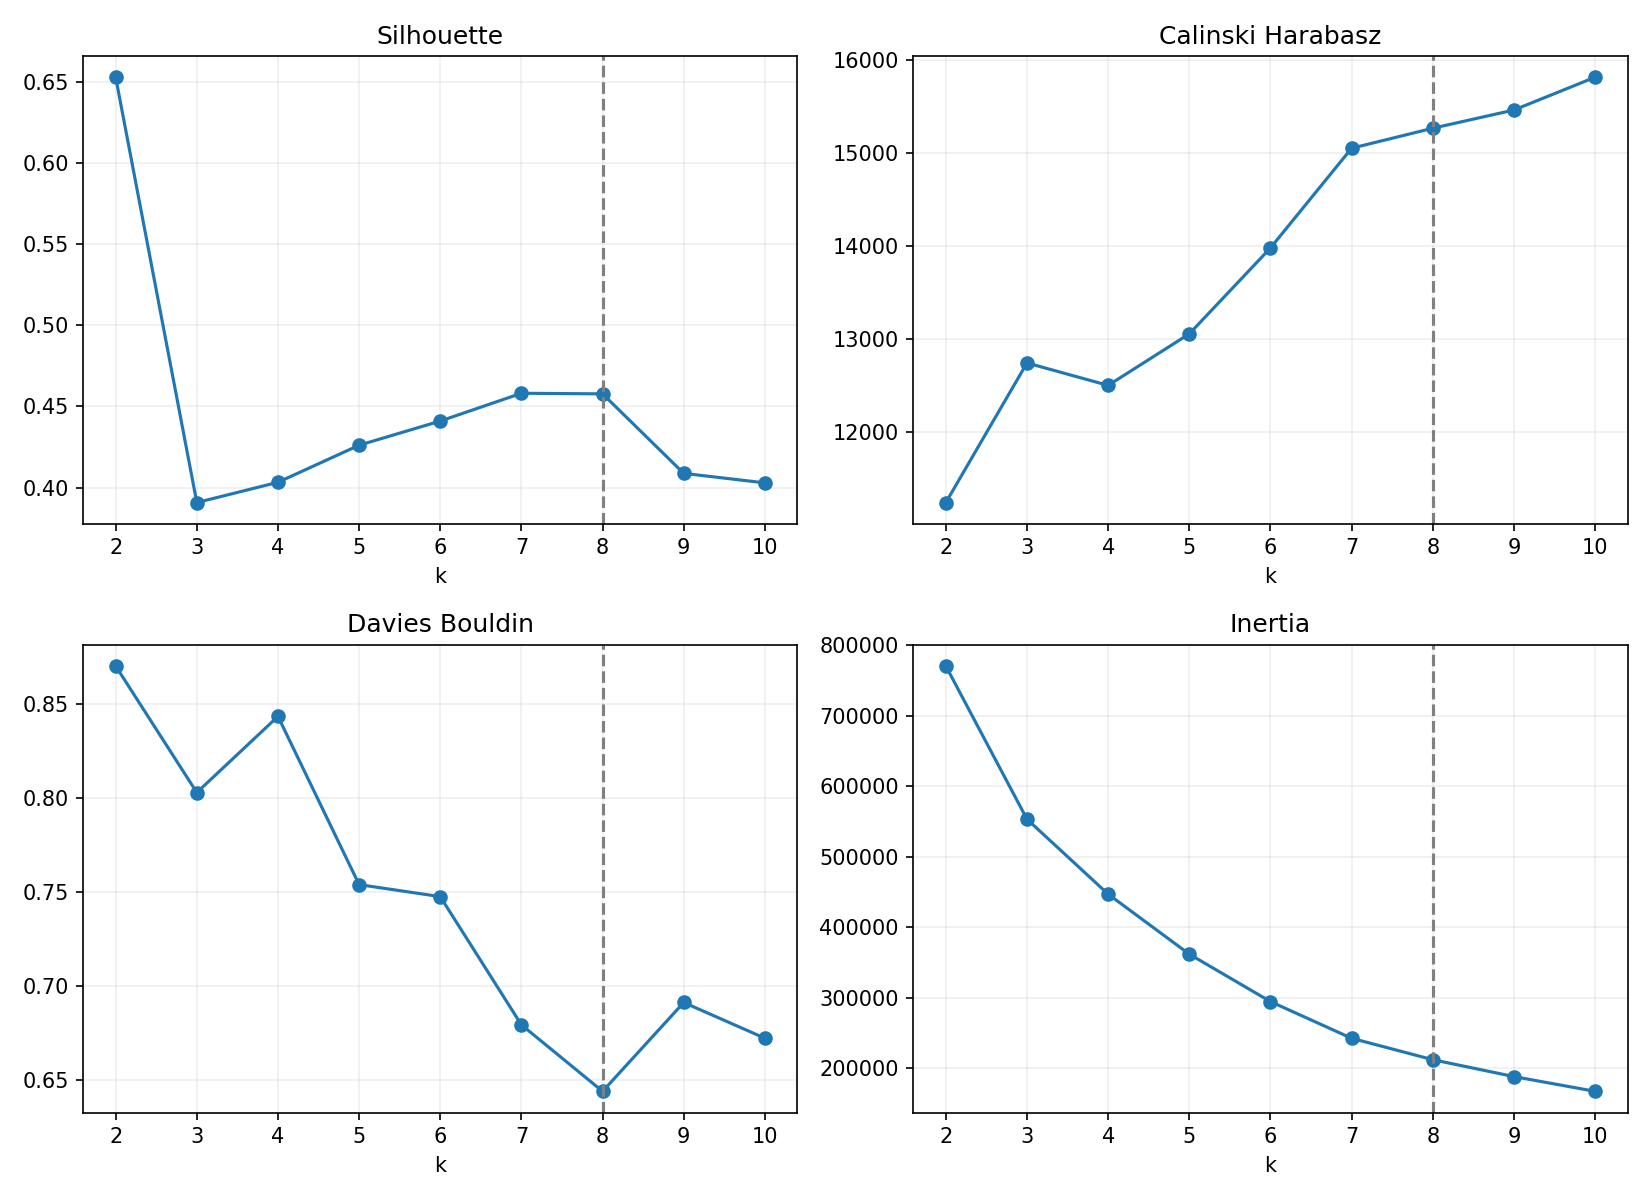

In [2]:
train_ids = np.flatnonzero(training.to_numpy())
sample_ids = rng.choice(train_ids, min(25000,len(train_ids)), replace=False)
S = X[sample_ids]
quality_ids = rng.choice(len(S), min(4000,len(S)), replace=False)
models, rows = {}, []
for k in range(2,11):
    m = KMeans(n_clusters=k, n_init=10, random_state=42).fit(S)
    labels = m.labels_
    models[k] = m
    rows.append(dict(k=k, silhouette=silhouette_score(S[quality_ids],labels[quality_ids]),
        calinski_harabasz=calinski_harabasz_score(S,labels),
        davies_bouldin=davies_bouldin_score(S,labels), inertia=m.inertia_))
quality = pd.DataFrame(rows)
quality['rank_sum'] = (quality.silhouette.rank(ascending=False)+
    quality.calinski_harabasz.rank(ascending=False)+quality.davies_bouldin.rank())
k = int(quality.loc[quality.rank_sum.idxmin(),'k'])
model = MiniBatchKMeans(n_clusters=k, init=models[k].cluster_centers_, n_init=1,
                       batch_size=8192, max_iter=150, random_state=42).fit(X[training])
# Fixed training-defined zones are used throughout, including the holdout and future forecasts.
df['cluster'] = model.predict(X)
final_labels = model.predict(S)
final_quality = dict(silhouette=silhouette_score(S[quality_ids], final_labels[quality_ids]),
    calinski_harabasz=calinski_harabasz_score(S,final_labels),
    davies_bouldin=davies_bouldin_score(S,final_labels))
quality.to_csv(ROOT/'cluster_quality_metrics.csv',index=False)
print(quality.round(4).to_string(index=False))
print('Selected k:',k,'; final MiniBatch model quality on training sample:',final_quality)
fig,axs=plt.subplots(2,2,figsize=(11,8))
for ax,col in zip(axs.flat,['silhouette','calinski_harabasz','davies_bouldin','inertia']):
    ax.plot(quality.k,quality[col],'-o'); ax.axvline(k,color='gray',ls='--')
    ax.set(title=col.replace('_',' ').title(),xlabel='k'); ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(FIG/'cluster_quality.png',dpi=150); plt.close(fig)



## 3. Geographic interpretation and fixed model centers

 cluster  center_lat  center_lon  trips  share_pct
       0    40.76537   -73.97407 368560   35.84740
       1    40.66818   -73.97703  71889    6.99217
       2    40.66211   -73.75906  30812    2.99688
       3    40.73047   -73.99807 407548   39.63950
       4    40.70978   -73.95040  75044    7.29903
       5    40.86412   -73.91129  21969    2.13678
       6    40.76060   -73.86755  42176    4.10218
       7    40.69508   -74.20450  10138    0.98606


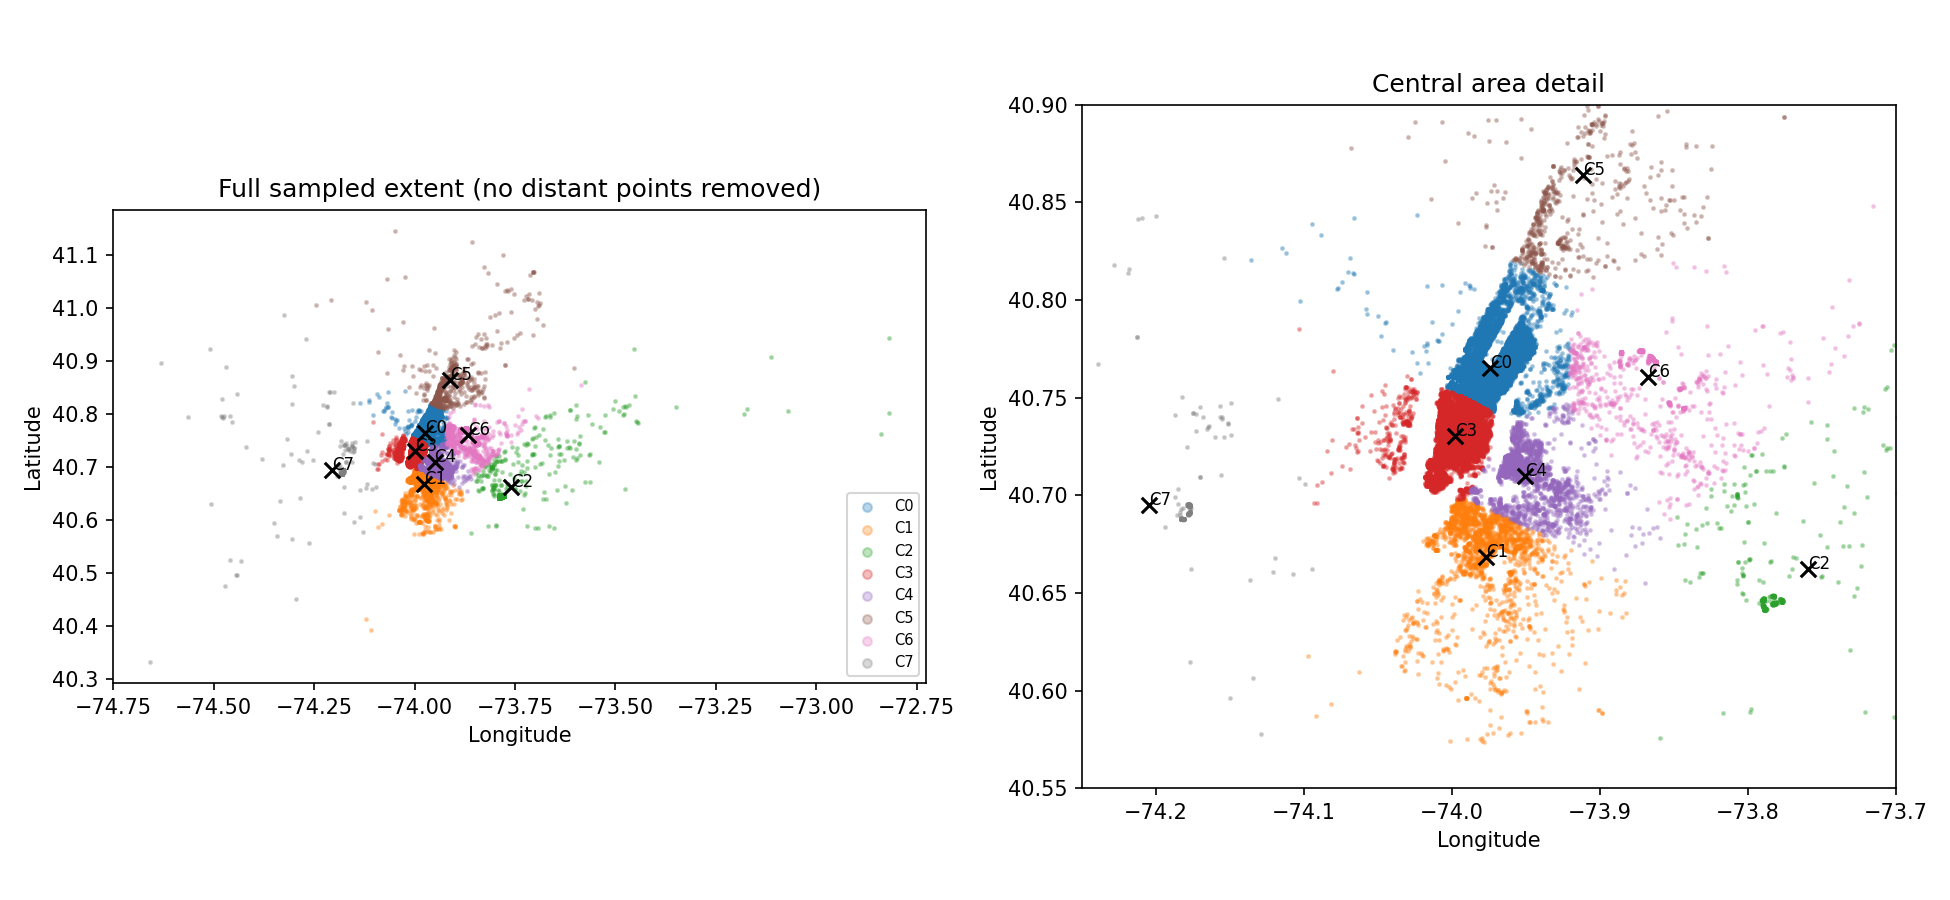

In [3]:
centers=pd.DataFrame({'cluster':range(k),'center_lat':model.cluster_centers_[:,1]/111.32+40.74,
                      'center_lon':model.cluster_centers_[:,0]/sx-74})
centers['trips']=df.cluster.value_counts().reindex(range(k),fill_value=0).to_numpy()
centers['share_pct']=100*centers.trips/len(df)
centers.to_csv(ROOT/'cluster_centers.csv',index=False)
print(centers.round(5).to_string(index=False))
colors=plt.get_cmap('tab10')
pidx=rng.choice(len(df),30000,replace=False)
fig,axs=plt.subplots(1,2,figsize=(13,6))
for ax in axs:
    for c in range(k):
        pts=df.iloc[pidx]; pts=pts[pts.cluster==c]
        ax.scatter(pts.Lon,pts.Lat,s=2,alpha=.3,color=colors(c),label=f'C{c}')
    ax.scatter(centers.center_lon,centers.center_lat,c='black',marker='x',s=55)
    for row in centers.itertuples(): ax.annotate(f'C{row.cluster}',(row.center_lon,row.center_lat),fontsize=8)
    ax.set(xlabel='Longitude',ylabel='Latitude'); ax.set_aspect(1/np.cos(np.deg2rad(40.74)))
axs[0].set_title('Full sampled extent (no distant points removed)')
axs[1].set(xlim=(-74.25,-73.7),ylim=(40.55,40.9),title='Central area detail')
axs[0].legend(markerscale=3,fontsize=7);fig.tight_layout();fig.savefig(FIG/'pickup_clusters.png',dpi=150);plt.close(fig)



## 4. Demand and empirical cluster centers by hour and date

 cluster  peak_hour  peak_date  max_hour_center_offset_km  max_date_center_offset_km  min_hour_group_n  min_date_group_n
       0         17 2014-09-05                      0.917                      0.319              2357              5602
       1         19 2014-09-13                      0.399                      0.497               645              1677
       2         14 2014-09-01                      7.691                      3.442               112               725
       3         18 2014-09-13                      0.183                      0.078              4337              6233
       4         21 2014-09-27                      0.600                      0.537              1494              1811
       5         21 2014-09-27                      1.962                      1.811               232               560
       6         20 2014-09-21                      1.131                      0.809               261              1001
       7         15 2014-09-01  

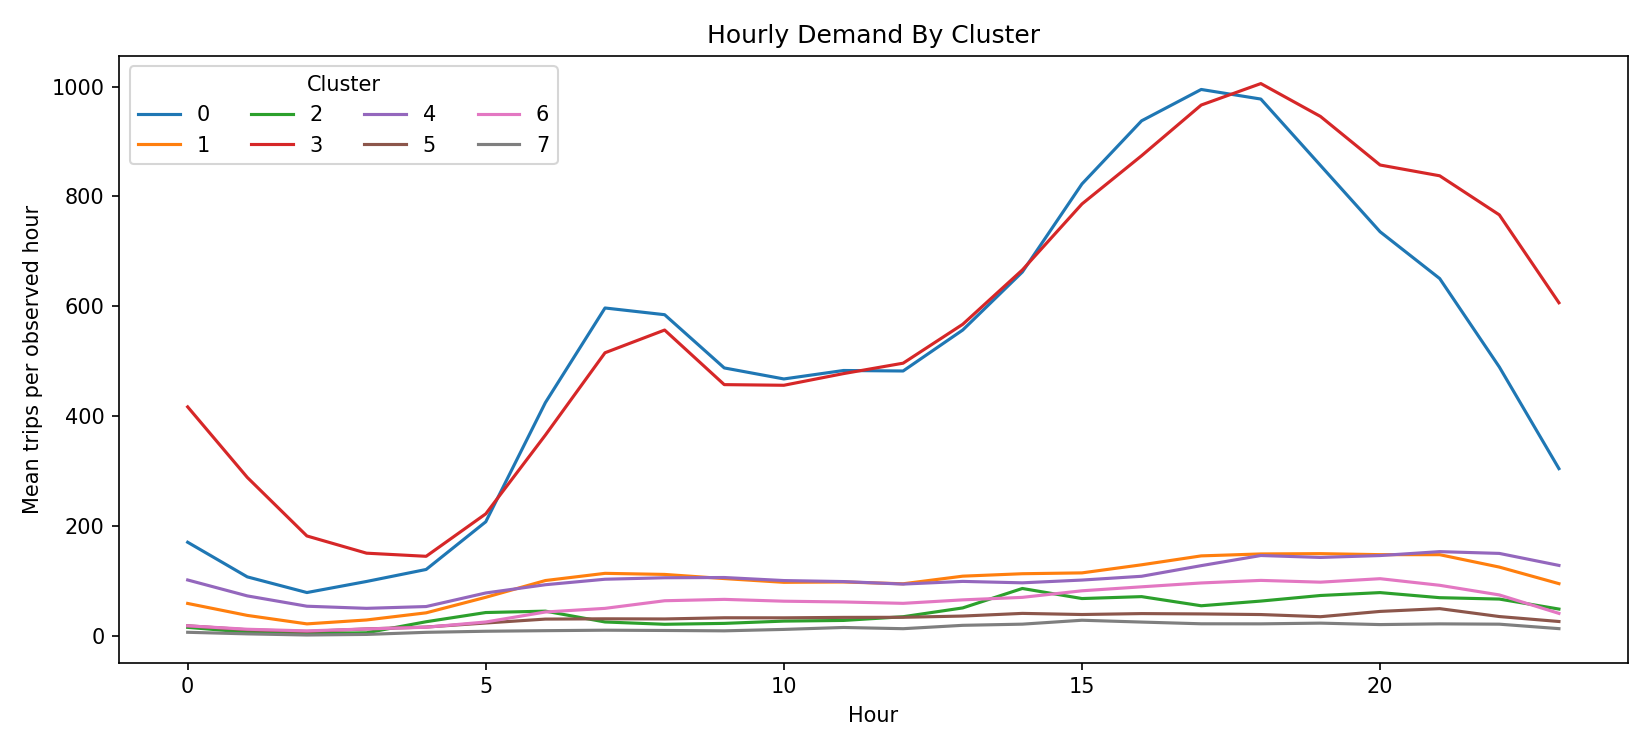

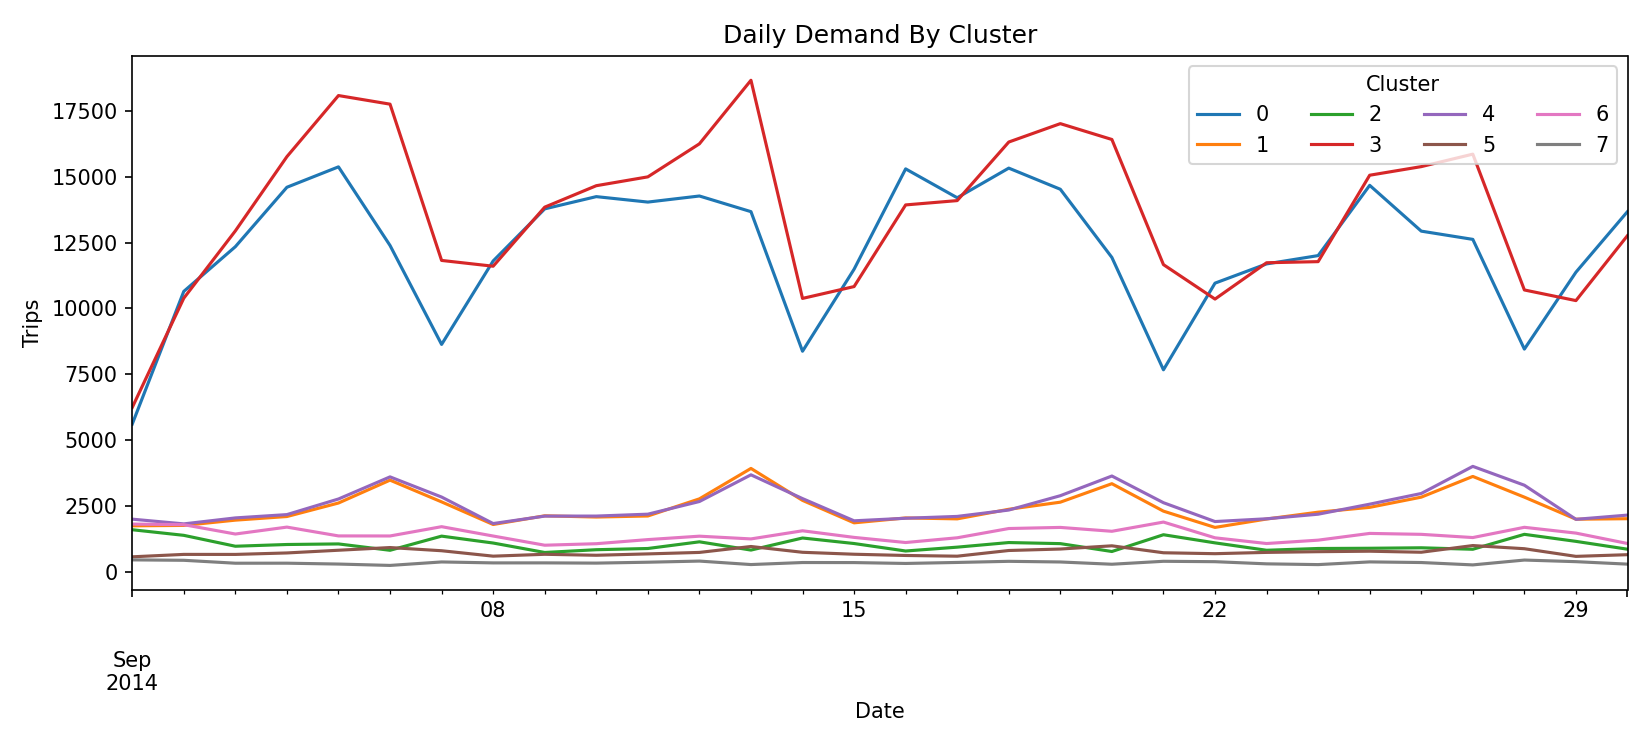

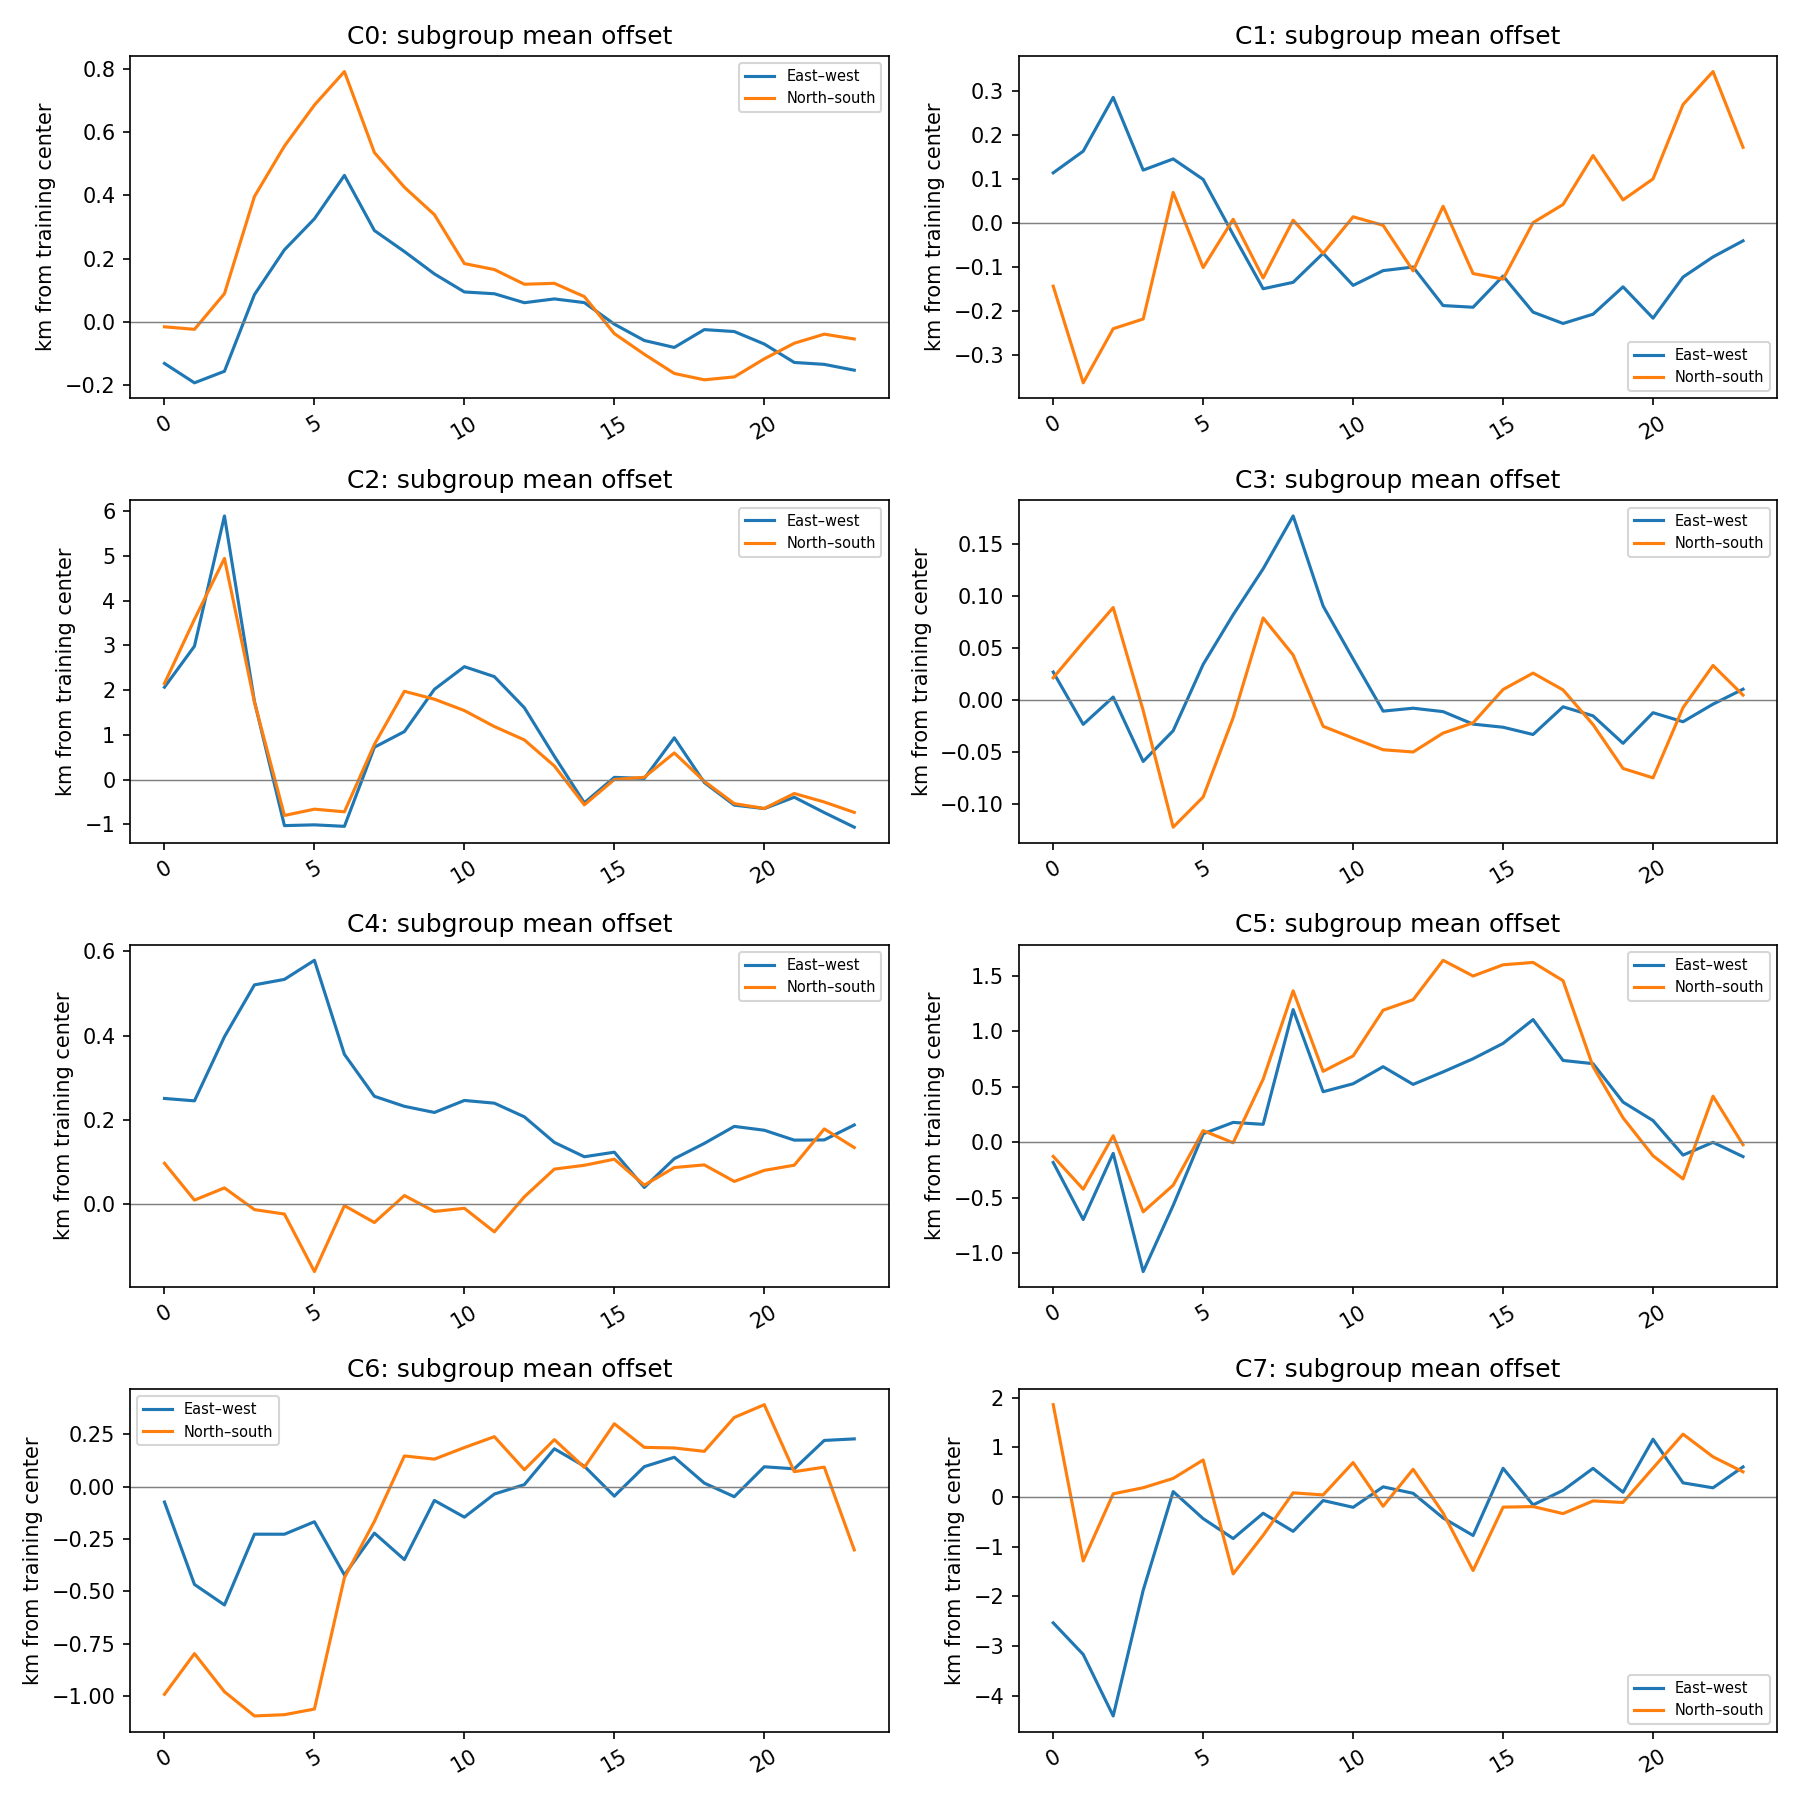

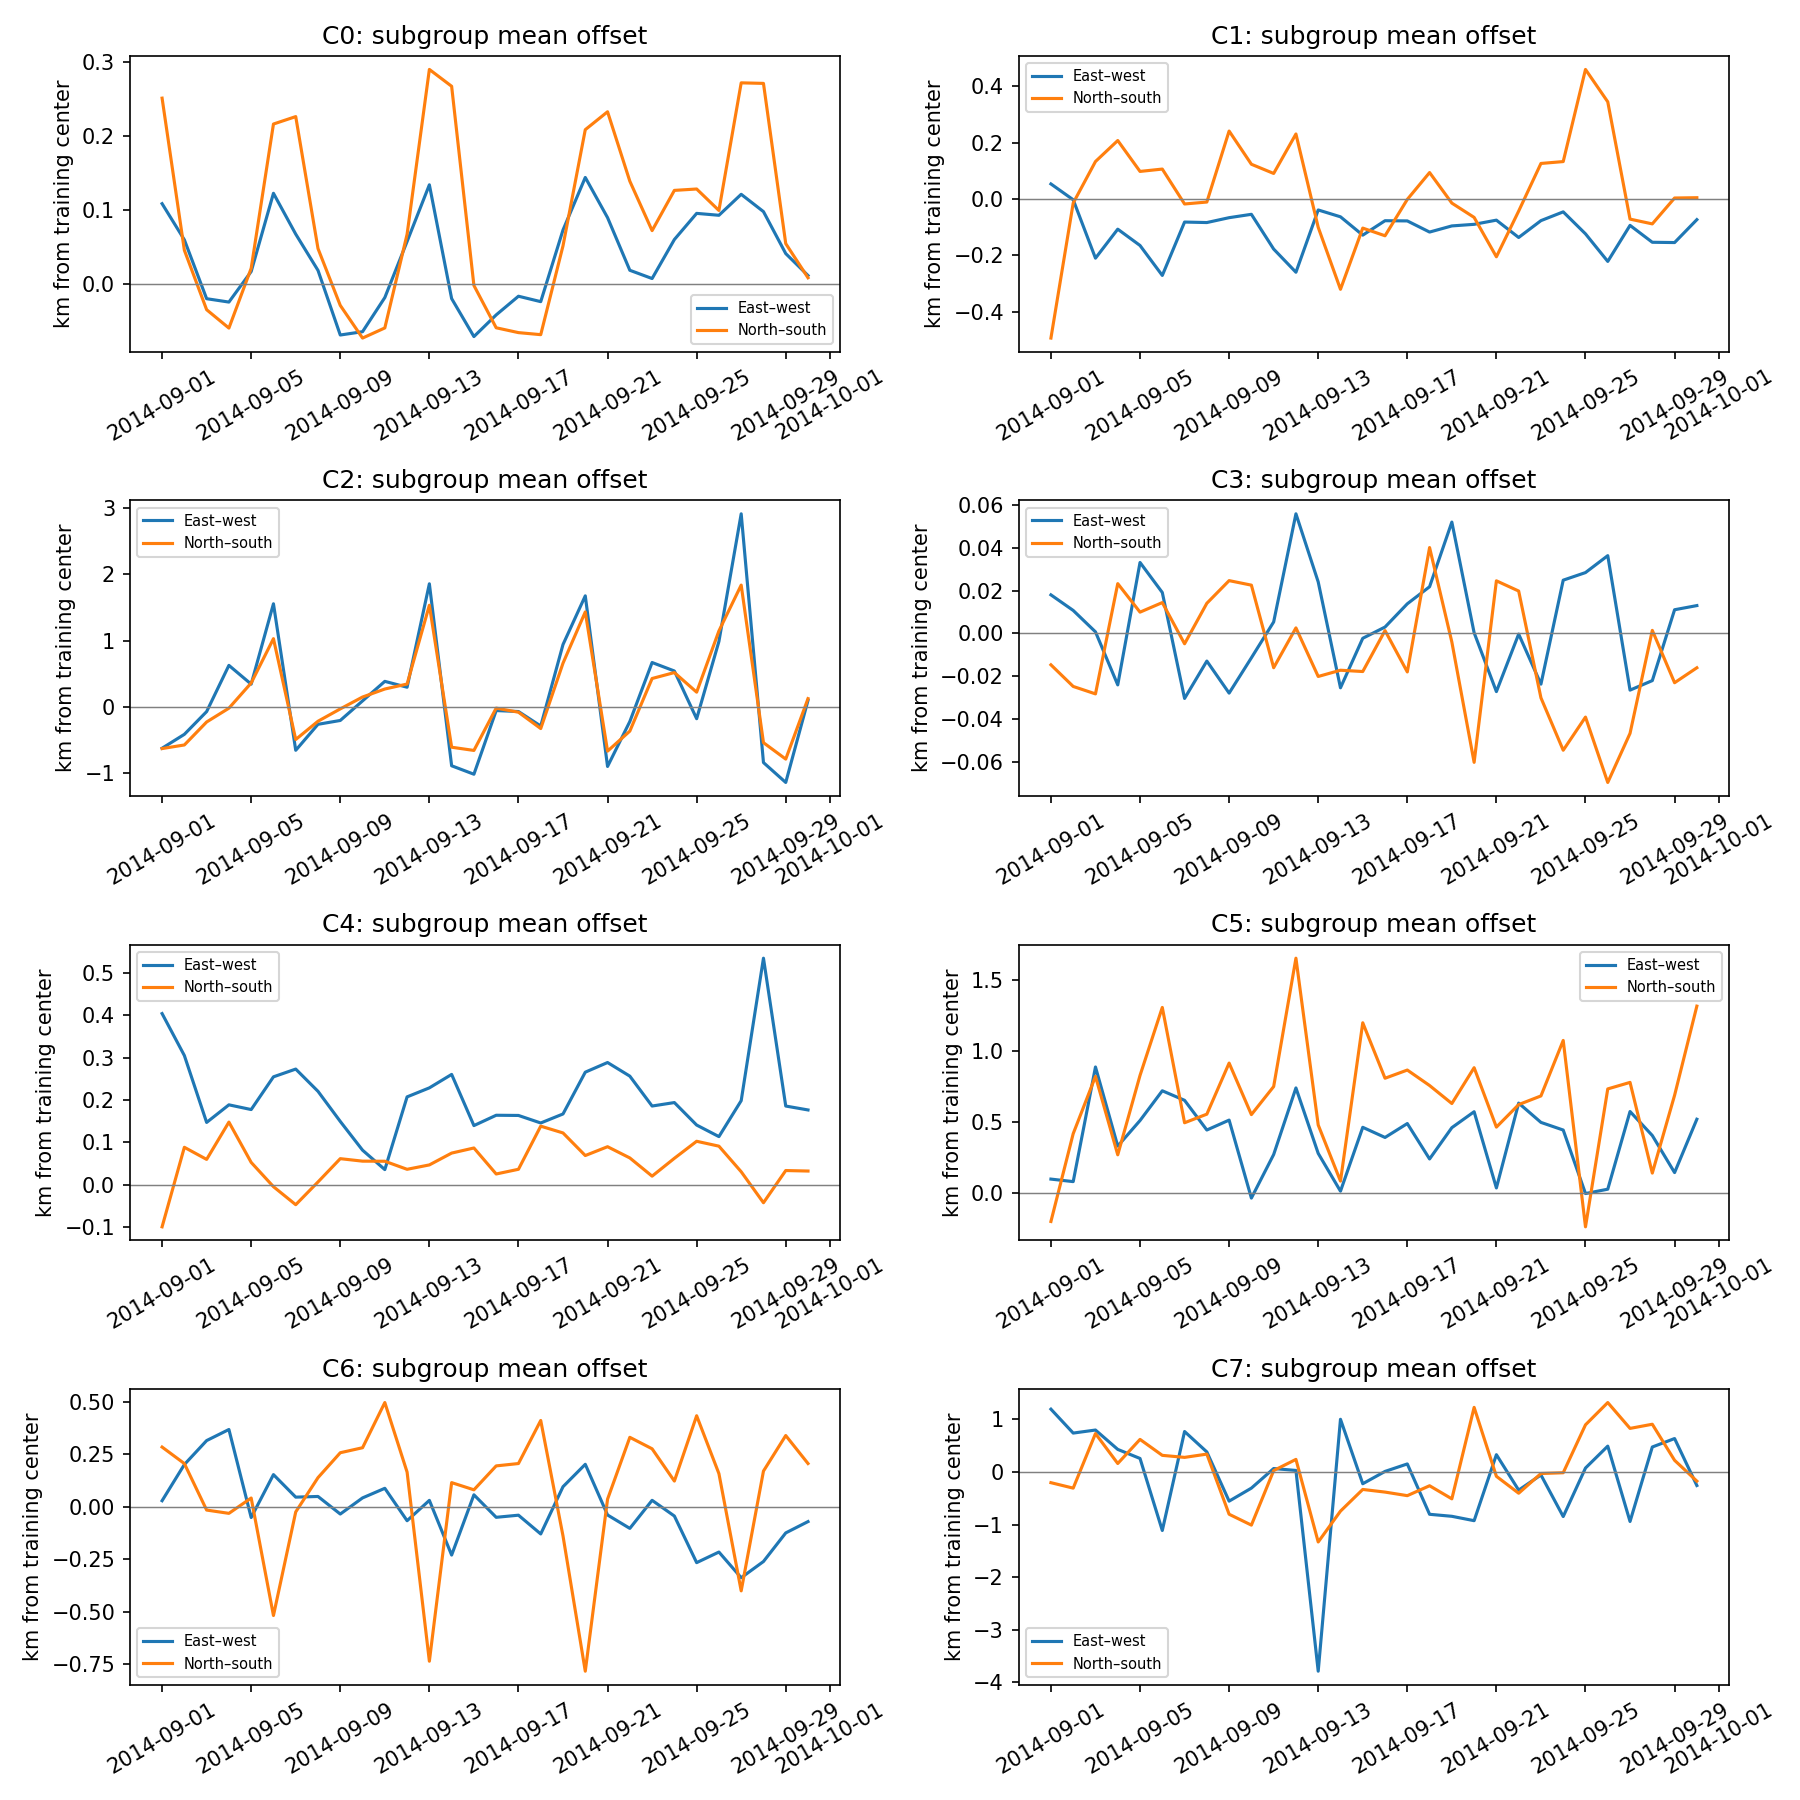

In [4]:
# Do not refit separate clusters: label switching would make center comparisons ambiguous.
# These are subgroup mean locations within the fixed zones, not moving model centers.
df['hour']=df.time.dt.hour; df['date']=df.time.dt.floor('D')
observed_index=pd.date_range(df.time.min().floor('h'),df.time.max().floor('h'),freq='h')
counts=(df.groupby([df.time.dt.floor('h'),'cluster']).size().unstack(fill_value=0)
        .reindex(index=observed_index,columns=range(k),fill_value=0))
exposure=pd.Series(observed_index.hour).value_counts().reindex(range(24))
hourly=df.groupby(['hour','cluster']).size().unstack(fill_value=0).reindex(range(24)).div(exposure,axis=0)
daily=counts.resample('D').sum()
for name,table,xlabel in [('hourly_demand_by_cluster',hourly,'Hour'),('daily_demand_by_cluster',daily,'Date')]:
    fig,ax=plt.subplots(figsize=(11,5))
    table.plot(ax=ax,color=[colors(c) for c in range(k)])
    ax.set(xlabel=xlabel,ylabel='Mean trips per observed hour' if xlabel=='Hour' else 'Trips',title=name.replace('_',' ').title())
    ax.legend(ncol=4,title='Cluster');fig.tight_layout();fig.savefig(FIG/(name+'.png'),dpi=150);plt.close(fig)
profiles={}
for field in ['hour','date']:
    tab=df.groupby(['cluster',field]).agg(n=('Lat','size'),lat=('Lat','mean'),lon=('Lon','mean')).reset_index()
    tab=tab.merge(centers[['cluster','center_lat','center_lon']],on='cluster')
    tab['east_km']=(tab.lon-tab.center_lon)*sx
    tab['north_km']=(tab.lat-tab.center_lat)*111.32
    tab['displacement_km']=np.hypot(tab.east_km,tab.north_km)
    tab.to_csv(ROOT/f'cluster_centers_by_{field}.csv',index=False)
    profiles[field]=tab
    fig,axs=plt.subplots((k+1)//2,2,figsize=(12,3*((k+1)//2)),squeeze=False)
    for c,ax in enumerate(axs.flat):
        if c>=k: ax.set_visible(False);continue
        s=tab[tab.cluster==c]
        ax.plot(s[field],s.east_km,label='East–west');ax.plot(s[field],s.north_km,label='North–south')
        ax.axhline(0,color='gray',lw=.7);ax.set(title=f'C{c}: subgroup mean offset',ylabel='km from training center')
        ax.tick_params(axis='x',rotation=30);ax.legend(fontsize=7)
    fig.tight_layout();fig.savefig(FIG/f'centers_by_{field}.png',dpi=150);plt.close(fig)
zone_rows=[]
for c in range(k):
    h=profiles['hour'].query('cluster == @c'); d=profiles['date'].query('cluster == @c')
    zone_rows.append(dict(cluster=c,peak_hour=int(hourly[c].idxmax()),peak_date=str(daily[c].idxmax().date()),
        max_hour_center_offset_km=h.displacement_km.max(),max_date_center_offset_km=d.displacement_km.max(),
        min_hour_group_n=int(h.n.min()),min_date_group_n=int(d.n.min())))
zone_summary=pd.DataFrame(zone_rows)
zone_summary.to_csv(ROOT/'temporal_cluster_summary.csv',index=False)
print(zone_summary.round(3).to_string(index=False))
print('Sep 30 has 23 observed hourly bins; 23:00 is unobserved, not assumed zero. Hourly profiles use exposure adjustment.')



## 5. Chronological forecasts and a weekly-naive comparison

            model cluster    MAE    RMSE  WAPE_pct
weekday_hour_mean       0 72.373 105.190    14.098
weekday_hour_mean       1 14.671  19.166    13.641
weekday_hour_mean       2 10.296  14.434    24.845
weekday_hour_mean       3 74.555 108.696    13.559
weekday_hour_mean       4 16.157  21.960    14.120
weekday_hour_mean       5  6.887   9.281    21.555
weekday_hour_mean       6 10.232  13.701    17.881
weekday_hour_mean       7  4.130   5.505    29.705
weekday_hour_mean     ALL 26.163  55.048    14.639
     weekly_naive       0 79.138 122.041    15.416
     weekly_naive       1 17.910  24.298    16.654
     weekly_naive       2 11.527  16.334    27.814
     weekly_naive       3 81.623 134.623    14.844
     weekly_naive       4 17.162  23.243    14.997
     weekly_naive       5  9.108  12.234    28.504
     weekly_naive       6 11.749  16.308    20.532
     weekly_naive       7  4.778   6.380    34.367
     weekly_naive     ALL 29.124  66.022    16.296
{
  "rows": 1028136,
  "selecte

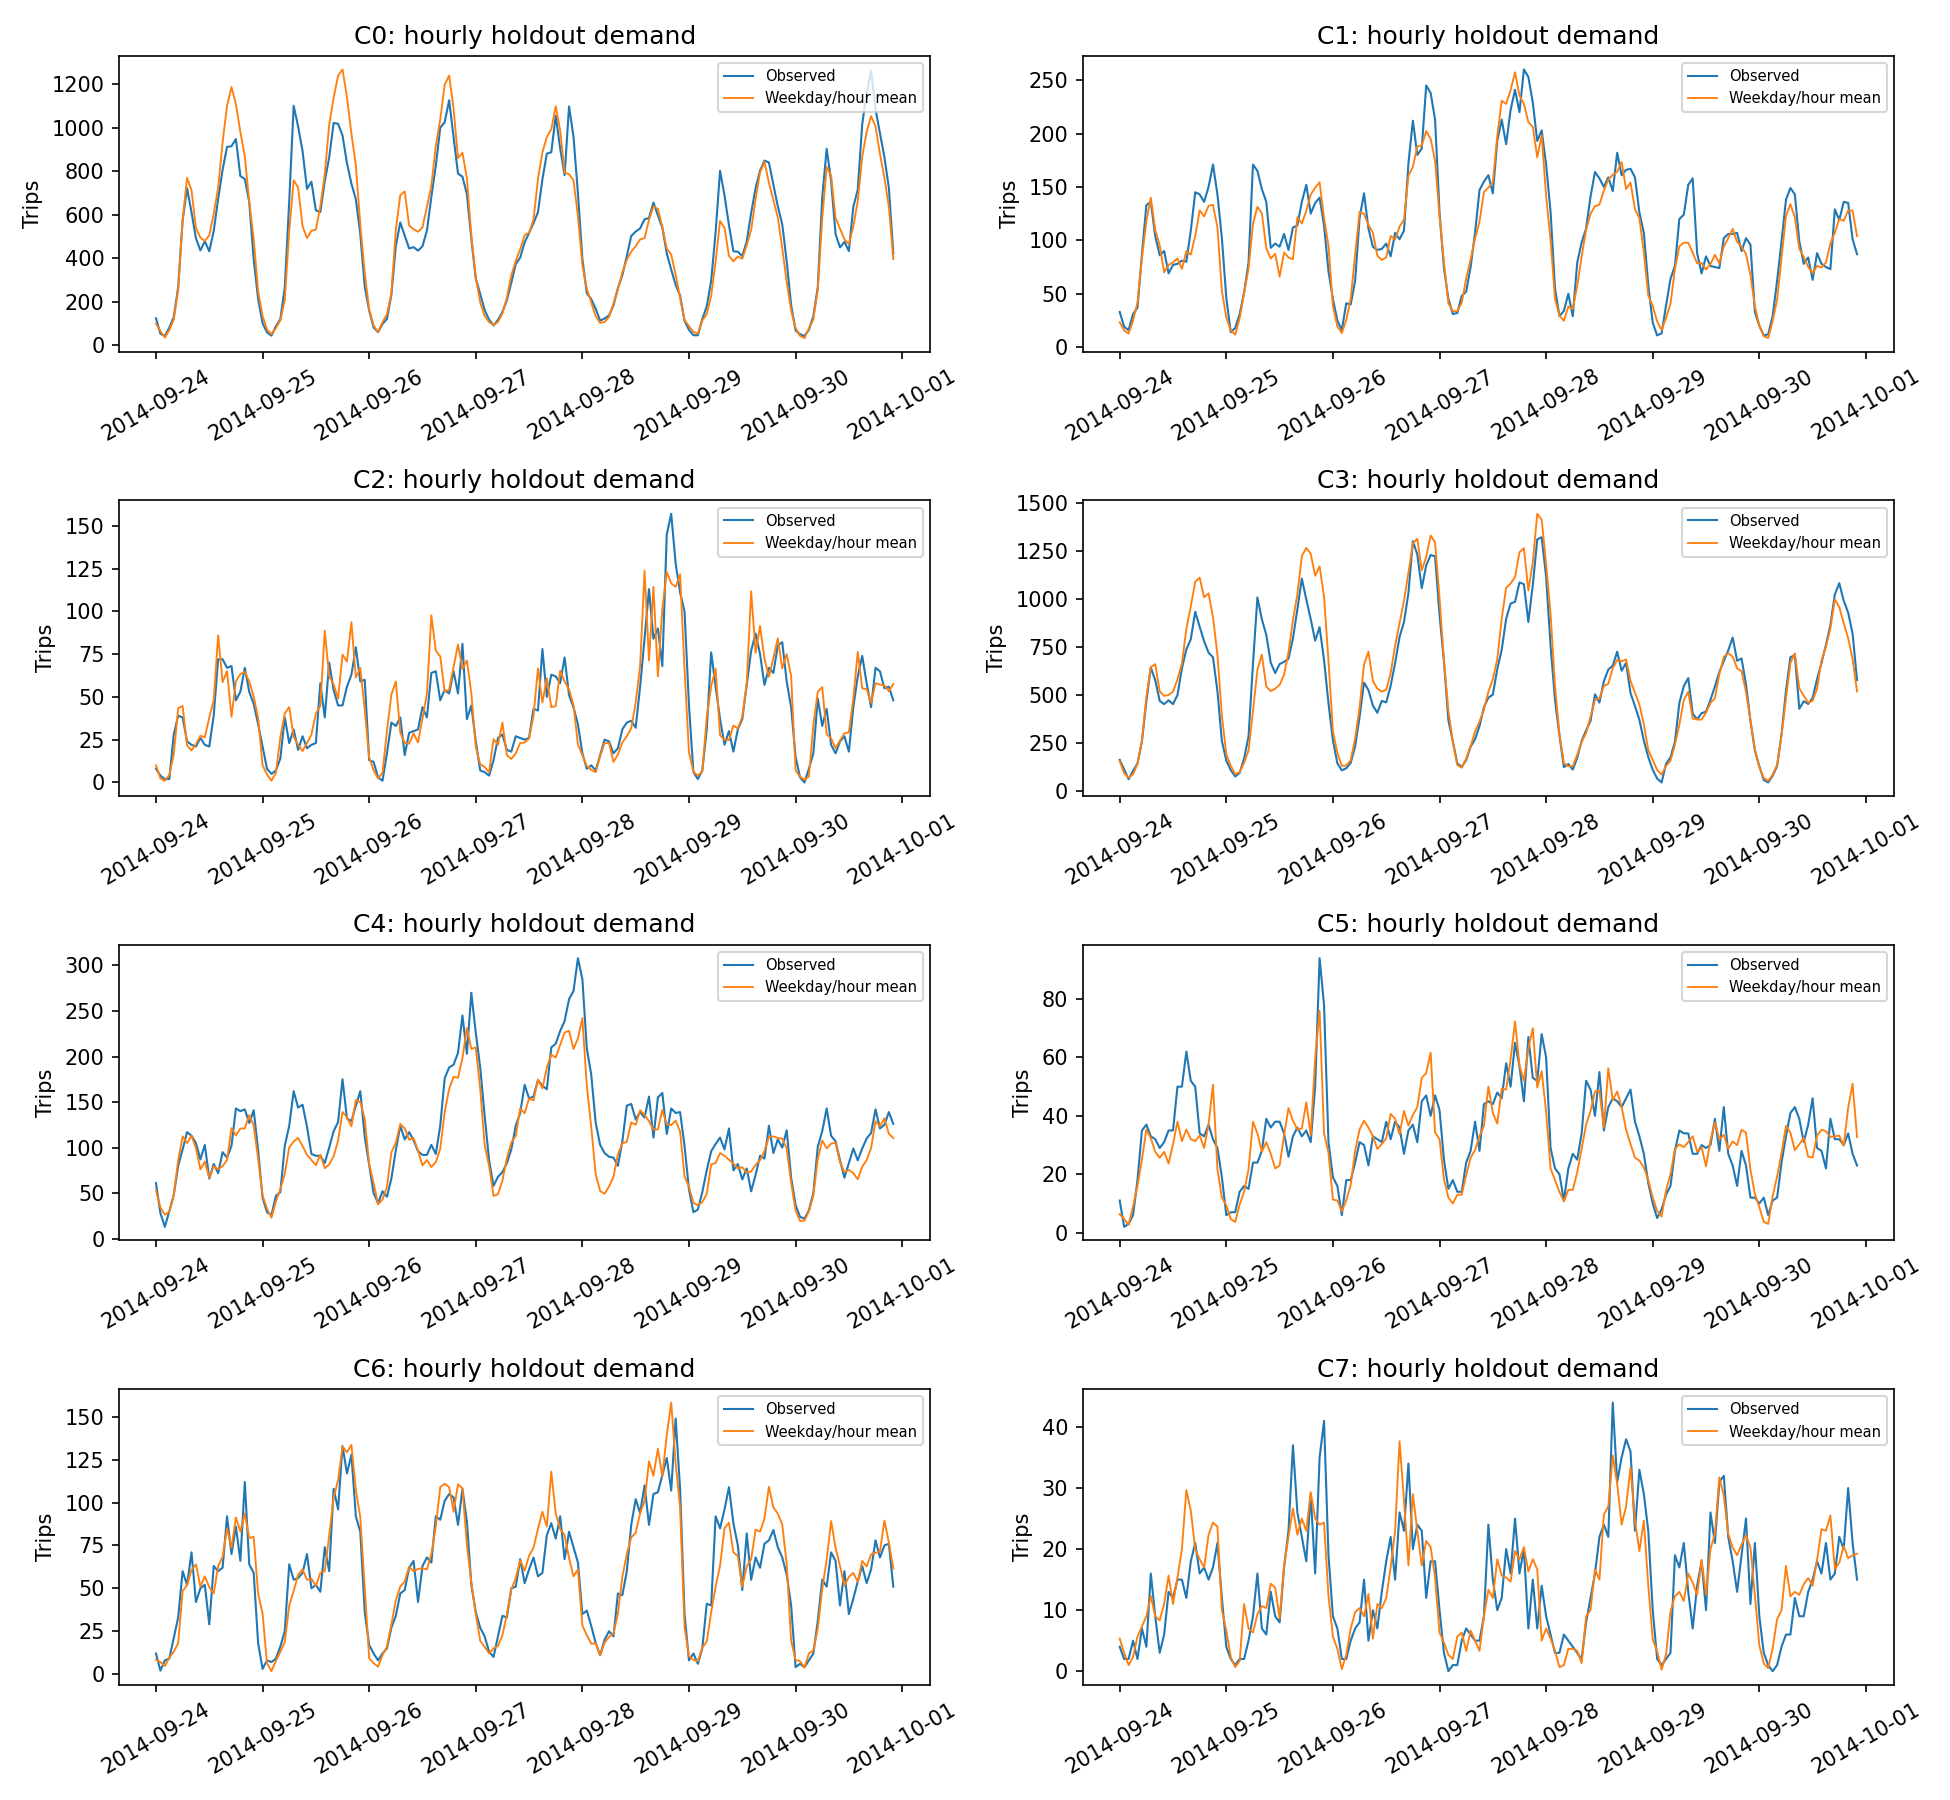

In [5]:
train=counts[counts.index<cutoff]; test=counts[counts.index>=cutoff]
def weekday_hour_prediction(history,index):
    means=history.groupby([history.index.dayofweek,history.index.hour]).mean()
    keys=pd.MultiIndex.from_arrays([index.dayofweek,index.hour])
    return pd.DataFrame(means.reindex(keys).to_numpy(),index=index,columns=history.columns)
pred=weekday_hour_prediction(train,test.index)
weekly=train.reindex(test.index-pd.Timedelta(days=7)).copy();weekly.index=test.index
assert not pred.isna().any().any() and not weekly.isna().any().any()
metric_rows=[]
for name,forecast in [('weekday_hour_mean',pred),('weekly_naive',weekly)]:
    for c in list(range(k))+['ALL']:
        a=test.to_numpy() if c=='ALL' else test[c].to_numpy()
        b=forecast.to_numpy() if c=='ALL' else forecast[c].to_numpy()
        e=a-b
        metric_rows.append(dict(model=name,cluster=c,MAE=np.abs(e).mean(),RMSE=np.sqrt((e*e).mean()),WAPE_pct=100*np.abs(e).sum()/a.sum()))
metrics=pd.DataFrame(metric_rows);metrics.to_csv(ROOT/'forecast_metrics.csv',index=False)
print(metrics.round(3).to_string(index=False))
future_index=pd.date_range('2014-10-01',periods=168,freq='h')
future=weekday_hour_prediction(counts,future_index)
future.to_csv(ROOT/'forecast_october_1_to_7.csv',index_label='timestamp')
fig,axs=plt.subplots((k+1)//2,2,figsize=(13,3*((k+1)//2)),squeeze=False)
for c,ax in enumerate(axs.flat):
    if c>=k: ax.set_visible(False); continue
    ax.plot(test.index,test[c],label='Observed',lw=1)
    ax.plot(pred.index,pred[c],label='Weekday/hour mean',lw=.9)
    ax.set(title=f'C{c}: hourly holdout demand',ylabel='Trips');ax.tick_params(axis='x',rotation=30);ax.legend(fontsize=7)
fig.tight_layout();fig.savefig(FIG/'forecast_holdout_week.png',dpi=150);plt.close(fig)
summary=dict(rows=len(df),selected_k_by_combined_rank=k,final_training_sample_quality=final_quality,
    cutoff=str(cutoff),holdout_hours=len(test),duplicates_retained=duplicates,
    forecast_wape_pct=float(metrics.query("model == 'weekday_hour_mean' and cluster == 'ALL'").WAPE_pct.iloc[0]),
    weekly_naive_wape_pct=float(metrics.query("model == 'weekly_naive' and cluster == 'ALL'").WAPE_pct.iloc[0]))
(ROOT/'analysis_summary.json').write_text(json.dumps(summary,indent=2))
print(json.dumps(summary,indent=2))


## Interpretation and limitations

### Algorithm and cluster count
K-means creates compact distance-based zones and assigns every pickup to a zone, making fixed-zone forecasting straightforward. MiniBatch K-means scales the final fit to the training records. DBSCAN could identify irregular density regions and noise, but density parameters and unassigned noise complicate exhaustive zone-demand forecasts; it was not empirically benchmarked here. Hierarchical and spectral methods require additional sampling or approximations at this scale.

Candidates k=2–10 were fitted with 10 K-means starts on a 25,000-record **training-only** sample. Silhouette uses 4,000 of those points; CH and DB use the full sample. Equal-weight rank aggregation selects **k=8**. The three indices are related internal measures, not independent votes, and rank aggregation is a heuristic, not proof of a globally optimal partition. The highest silhouette occurs at k=2. Candidate metrics and final MiniBatch model metrics are reported separately.

### Location and demand differences
| cluster | center_lat | center_lon | trips | share_pct |
|---|---|---|---|---|
| 0 | 40.765 | -73.974 | 368560 | 35.847 |
| 1 | 40.668 | -73.977 | 71889 | 6.992 |
| 2 | 40.662 | -73.759 | 30812 | 2.997 |
| 3 | 40.730 | -73.998 | 407548 | 39.639 |
| 4 | 40.710 | -73.950 | 75044 | 7.299 |
| 5 | 40.864 | -73.911 | 21969 | 2.137 |
| 6 | 40.761 | -73.868 | 42176 | 4.102 |
| 7 | 40.695 | -74.204 | 10138 | 0.986 |

Cluster numbers are identifiers, not a ranking. Centers give approximate geographic locations; zones need not match administrative boundaries. All valid-coordinate trips, including distant points, remain in the analysis. K-means and subgroup averages can be influenced by those distant trips.

| cluster | peak_hour | peak_date | max_hour_center_offset_km | max_date_center_offset_km | min_hour_group_n | min_date_group_n |
|---|---|---|---|---|---|---|
| 0 | 17 | 2014-09-05 | 0.917 | 0.319 | 2357 | 5602 |
| 1 | 19 | 2014-09-13 | 0.399 | 0.497 | 645 | 1677 |
| 2 | 14 | 2014-09-01 | 7.691 | 3.442 | 112 | 725 |
| 3 | 18 | 2014-09-13 | 0.183 | 0.078 | 4337 | 6233 |
| 4 | 21 | 2014-09-27 | 0.600 | 0.537 | 1494 | 1811 |
| 5 | 21 | 2014-09-27 | 1.962 | 1.811 | 232 | 560 |
| 6 | 20 | 2014-09-21 | 1.131 | 0.809 | 261 | 1001 |
| 7 | 15 | 2014-09-01 | 4.403 | 4.017 | 37 | 233 |

- C0 accounts for 35.85% of pickups. Its exposure-adjusted hourly peak is 17:00 and its highest recorded daily count occurs on 2014-09-05. The largest hourly subgroup-center offset is 0.92 km; the largest daily offset is 0.32 km.
- C1 accounts for 6.99% of pickups. Its exposure-adjusted hourly peak is 19:00 and its highest recorded daily count occurs on 2014-09-13. The largest hourly subgroup-center offset is 0.40 km; the largest daily offset is 0.50 km.
- C2 accounts for 3.00% of pickups. Its exposure-adjusted hourly peak is 14:00 and its highest recorded daily count occurs on 2014-09-01. The largest hourly subgroup-center offset is 7.69 km; the largest daily offset is 3.44 km.
- C3 accounts for 39.64% of pickups. Its exposure-adjusted hourly peak is 18:00 and its highest recorded daily count occurs on 2014-09-13. The largest hourly subgroup-center offset is 0.18 km; the largest daily offset is 0.08 km.
- C4 accounts for 7.30% of pickups. Its exposure-adjusted hourly peak is 21:00 and its highest recorded daily count occurs on 2014-09-27. The largest hourly subgroup-center offset is 0.60 km; the largest daily offset is 0.54 km.
- C5 accounts for 2.14% of pickups. Its exposure-adjusted hourly peak is 21:00 and its highest recorded daily count occurs on 2014-09-27. The largest hourly subgroup-center offset is 1.96 km; the largest daily offset is 1.81 km.
- C6 accounts for 4.10% of pickups. Its exposure-adjusted hourly peak is 20:00 and its highest recorded daily count occurs on 2014-09-21. The largest hourly subgroup-center offset is 1.13 km; the largest daily offset is 0.81 km.
- C7 accounts for 0.99% of pickups. Its exposure-adjusted hourly peak is 15:00 and its highest recorded daily count occurs on 2014-09-01. The largest hourly subgroup-center offset is 4.40 km; the largest daily offset is 4.02 km.

### What “center changes” means
The trained model centers stay fixed. For each zone, the report separately calculates the average pickup latitude/longitude by hour of day (pooled over the month) and by calendar date. Offset plots show those empirical subgroup means relative to the fixed training center. Thus they measure changing pickup composition **within a zone**, not a refitted cluster or a moving vehicle. Among these zones, C3 has the smallest maximum daily offset (0.08 km), while C7 has the largest (4.02 km). Counts accompany every center estimate; small groups and outliers can amplify shifts, so these differences are descriptive rather than significance tests.

September 30 ends at 22:59 in the file. Its 23:00 bin is unobserved and excluded, not filled with zero. Daily totals for September 30 cover only 23 observed hours; hourly profiles divide by observed exposure (29 observations of hour 23, 30 of the other hours).

### Forecast results
The weekday/hour mean was specified before evaluating the holdout. It achieves **14.64% WAPE**, versus **16.30%** for using the same hour one week earlier. ALL-row MAE/RMSE average zone-hour errors; ALL WAPE sums absolute zone-hour errors divided by all test trips, so it is not the error of aggregated citywide totals. Neither model uses holdout demand to generate holdout predictions. K selection and geographic centers also exclude the holdout.

For October 1–7, demand profiles are refitted on all observed September demand while the geographic zone definitions stay fixed. No October actual outcomes are supplied, so those future forecasts cannot be verified here. One month and one holdout week limit generalization; events, weather, long-term trends, and annual seasonality are absent. This is an interpretable baseline, not a claim of optimal predictive performance.
